# DSCI 552 — Homework 4

**Name:** Gina Mao  
**GitHub Username:** ruoxuanm116  
**USC ID:** 8885483334

## Imports and global settings

In [4]:
import os
import re
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_curve, roc_auc_score, auc,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.exceptions import ConvergenceWarning

# Unpenalised logistic regression on (almost) separable data does not converge by design
# (footnote 5 of the assignment asks us to stop it early with max_iter), so these warnings are expected.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
# Some activities have only 4-5 training instances, fewer than 5 folds -> sklearn emits a UserWarning.
warnings.filterwarnings("ignore", message=".*least populated class.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)

import sklearn
SKLEARN_GE_18 = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)


def l1_logreg(C, solver, **kw):
    # L1-penalised LogisticRegression that works on both old and new scikit-learn
    # (from version 1.8 the `penalty` argument is deprecated in favour of `l1_ratio`).
    if SKLEARN_GE_18:
        return LogisticRegression(C=C, l1_ratio=1.0, solver=solver, **kw)
    return LogisticRegression(C=C, penalty="l1", solver=solver, **kw)


RANDOM_STATE = 552
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = "../data/AReM"
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

# 1. Time Series Classification Part 1: Feature Creation/Extraction

(Part 1 was the programming assignment of Homework 3. Its code is re-included here because the
feature extraction is needed for Part 2.)

## 1(a) Load the AReM data

Some files need minor cleaning:
* `bending2/dataset4.csv` is space-separated instead of comma-separated;
* `cycling/dataset9.csv` and `cycling/dataset14.csv` have trailing commas on some lines;
* `sitting/dataset8.csv` has 479 rows instead of 480.

The loader below therefore skips the `#` header lines, splits each line on commas **or** white space,
and keeps the first 7 tokens (`time` + 6 series).

In [5]:
def load_instance(path):
    """Read one AReM file robustly and return a DataFrame with the 6 time series."""
    records = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t]
            records.append([float(t) for t in tokens[:7]])
    df = pd.DataFrame(records, columns=["time"] + SERIES)
    return df[SERIES].reset_index(drop=True)


ACTIVITIES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
instances = []
for act in ACTIVITIES:
    files = sorted(glob.glob(f"{DATA_DIR}/{act}/dataset*.csv"),
                   key=lambda p: int(re.findall(r"dataset(\d+)", p)[0]))
    for f in files:
        num = int(re.findall(r"dataset(\d+)", f)[0])
        instances.append({"activity": act, "dataset": num, "data": load_instance(f)})

print("Activities:", ACTIVITIES)
print("Number of instances:", len(instances))
print("Lengths of the series:", pd.Series([len(i['data']) for i in instances]).value_counts().to_dict())
instances[0]["data"].head()

Activities: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Number of instances: 88
Lengths of the series: {480: 87, 479: 1}


,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,39.25,0.43,22.75,0.43,33.75,1.3
1,39.25,0.43,23.00,0.00,33.00,0.0
2,39.25,0.43,23.25,0.43,33.00,0.0
3,39.50,0.50,23.00,0.71,33.00,0.0
4,39.50,0.50,24.00,0.00,33.00,0.0


## 1(b) Train/test split

Test data: datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2, 3 of every other activity.
All other datasets are training data.

In [6]:
for inst in instances:
    test_ids = (1, 2) if inst["activity"] in ("bending1", "bending2") else (1, 2, 3)
    inst["split"] = "test" if inst["dataset"] in test_ids else "train"

train_inst = [i for i in instances if i["split"] == "train"]
test_inst = [i for i in instances if i["split"] == "test"]
print(f"Train instances: {len(train_inst)}, Test instances: {len(test_inst)}")
pd.crosstab(pd.Series([i["activity"] for i in instances], name="activity"),
            pd.Series([i["split"] for i in instances], name="split"))

Train instances: 69, Test instances: 19


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


## 1(c) Feature extraction

### 1(c)i Time-domain features commonly used in time-series classification

* **Location / central tendency:** mean, median, mode, trimmed mean
* **Spread / dispersion:** standard deviation, variance, range (max − min), interquartile range, mean absolute deviation
* **Order statistics:** minimum, maximum, quartiles / percentiles
* **Shape of the distribution:** skewness, kurtosis
* **Energy / magnitude:** root mean square (RMS), signal energy (sum of squares), signal magnitude area
* **Temporal-dynamics features:** zero-crossing rate, mean-crossing rate, number of peaks, autocorrelation at different lags, slope of a linear trend, mean of first differences
* **Complexity:** entropy (e.g. sample/approximate entropy), Hjorth parameters

### 1(c)ii Extract min, max, mean, median, std, 1st quartile and 3rd quartile of all 6 series

The function below is written in general form: it can split each series into `l` (approximately)
equal parts — this is reused in Part 2. With `l = 1` it produces the 42 features of the table requested.

In [7]:
ALL_FEATURES = ["min", "max", "mean", "median", "std", "q1", "q3"]

FEATURE_FUNCS = {
    "min": lambda s: s.min(),
    "max": lambda s: s.max(),
    "mean": lambda s: s.mean(),
    "median": lambda s: np.median(s),
    "std": lambda s: s.std(ddof=1),
    "q1": lambda s: np.percentile(s, 25),
    "q3": lambda s: np.percentile(s, 75),
}


def extract_features(inst_list, l=1, features=ALL_FEATURES, series_idx=range(1, 7)):
    """Split each of the 6 series of every instance into l (approximately) equal parts and
    compute time-domain features of every part.

    Column names: '<feature>_<k>' where k = 1..6*l is the index of the (sub-)time series.
    Sub-series k = (part-1)*6 + series, i.e. for l = 2: 1..6 are the first halves of the 6 series,
    7..12 the second halves.
    """
    rows = []
    for inst in inst_list:
        arr = inst["data"].values
        parts = np.array_split(np.arange(len(arr)), l)
        row = {}
        for p, idx in enumerate(parts):
            for s in series_idx:
                k = p * 6 + s
                x = arr[idx, s - 1]
                for f in features:
                    row[f"{f}_{k}"] = FEATURE_FUNCS[f](x)
        rows.append(row)
    return pd.DataFrame(rows)


def describe(col, l):
    # translate a column name such as 'mean_11' into 'mean of avg_rss23, part 2 of l'
    f, k = col.rsplit("_", 1)
    k = int(k)
    return f"{f} of {SERIES[(k - 1) % 6]}, part {(k - 1) // 6 + 1} of {l}"


feat_all = extract_features(instances, l=1)
# columns: min_1 max_1 mean_1 median_1 std_1 q1_1 q3_1 ... (q1 = 1st quartile, q3 = 3rd quartile)
feat_all.insert(0, "Instance", np.arange(1, len(instances) + 1))
feat_table = feat_all.copy()
feat_table["activity"] = [i["activity"] for i in instances]
feat_table["split"] = [i["split"] for i in instances]
print(feat_table.shape)
feat_table.head(10)

(88, 45)


,Instance,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6,activity,split
0,1,37.25,45.00,40.624792,40.50,1.476967,39.2500,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.000,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.00,1.30,bending1,test
1,2,38.00,45.67,42.812812,42.50,1.435550,42.0000,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.000,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.00,1.30,bending1,test
2,3,35.00,47.40,43.954500,44.33,1.558835,43.0000,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.000,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,train
3,4,33.00,47.75,42.179812,43.50,3.670666,39.1500,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.000,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,train
4,5,33.00,45.75,41.678063,41.75,2.243490,41.3300,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.000,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,train
5,6,37.00,48.00,43.454958,43.25,1.386098,42.5000,45.00,0.0,1.58,0.378083,0.47,0.315566,0.00,0.5000,5.75,27.00,15.793333,15.000,3.847638,13.00,18.2700,0.0,10.03,0.849354,0.50,0.995761,0.43,1.120,8.00,33.50,23.034792,23.500,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,train
6,7,36.25,48.00,43.969125,44.50,1.618364,43.3100,44.67,0.0,1.50,0.413125,0.47,0.263111,0.43,0.5000,1.50,26.33,15.868021,16.250,3.742420,14.25,18.0000,0.0,5.17,0.666354,0.47,0.788985,0.00,0.940,11.33,30.75,22.103750,21.670,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,train
7,8,12.75,51.00,24.562958,24.25,3.737514,23.1875,26.50,0.0,6.87,0.590833,0.43,0.837408,0.00,0.7100,0.00,25.33,19.121333,20.250,4.299612,18.00,22.0000,0.0,6.76,0.736771,0.47,0.927048,0.00,0.870,10.67,30.00,23.493042,23.750,3.693786,20.5000,27.00,0.0,4.97,0.700188,0.50,0.693720,0.43,0.87,bending2,test
8,9,0.00,42.75,27.464604,28.00,3.583582,25.5000,30.00,0.0,7.76,0.449708,0.43,0.767197,0.00,0.5000,7.50,35.00,20.842542,20.750,3.826268,18.00,22.5000,0.0,5.76,0.779917,0.50,0.904436,0.00,0.940,0.00,33.00,17.617938,18.000,5.053642,15.0000,20.75,0.0,6.76,1.122125,0.83,1.012342,0.47,1.30,bending2,test
9,10,21.00,50.00,32.586208,33.00,6.238143,26.1875,34.50,0.0,9.90,0.516125,0.43,0.789957,0.00,0.8225,0.00,28.25,13.941625,14.250,5.883266,10.00,18.0000,0.0,7.40,0.868896,0.50,1.027013,0.43,1.120,5.00,33.75,20.345708,19.585,5.032424,17.6700,23.50,0.0,13.61,1.162042,0.83,1.332980,0.47,1.30,bending2,train


### 1(c)iii Standard deviation of each feature and 90% bootstrap confidence interval

For each of the 42 features we compute the sample standard deviation across the 88 instances and a
90% percentile-bootstrap confidence interval (B = 2000 bootstrap samples of the 88 instances).

In [8]:
def bootstrap_std_ci(x, B=2000, alpha=0.10, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    x = np.asarray(x)
    boot = np.array([rng.choice(x, size=len(x), replace=True).std(ddof=1) for _ in range(B)])
    return np.percentile(boot, 100 * alpha / 2), np.percentile(boot, 100 * (1 - alpha / 2))


rng = np.random.default_rng(RANDOM_STATE)
ci_rows = []
for col in feat_all.columns.drop("Instance"):
    lo, hi = bootstrap_std_ci(feat_all[col], rng=rng)
    ci_rows.append({"feature": col, "std": feat_all[col].std(ddof=1), "CI 5%": lo, "CI 95%": hi})
std_ci = pd.DataFrame(ci_rows).set_index("feature")
std_ci.round(3)

,std,CI 5%,CI 95%
feature,,,
min_1,9.570,8.253,10.761
max_1,4.394,3.356,5.269
mean_1,5.336,4.706,5.887
median_1,5.440,4.794,5.987
std_1,1.772,1.571,1.951
q1_1,6.154,5.568,6.646
q3_1,5.139,4.343,5.839
min_2,0.000,0.000,0.000
max_2,5.063,4.621,5.402


### 1(c)iv Selecting the three most important time-domain features

To support the judgement, the cell below computes, for every feature type and every series,
the one-way ANOVA F-statistic of the feature across the 7 activities (large F = the feature
separates the activities well), and averages it over the 6 series. We also look at how correlated
the feature types are with each other (redundancy).

,series 1,series 2,series 3,series 4,series 5,series 6,mean F (ignoring NaN)
mean,21.1,918.6,34.7,841.3,54.6,815.8,447.7
q3,13.2,819.4,41.6,702.8,51.1,860.3,414.7
median,21.3,564.4,27.1,1012.0,45.7,743.3,402.3
q1,26.1,347.1,25.5,313.7,43.4,448.1,200.7
std,10.1,462.0,16.0,166.2,8.7,194.0,142.9
max,1.9,70.2,44.4,35.6,56.5,46.8,42.6
min,16.5,NaN,24.6,NaN,40.6,0.8,20.6


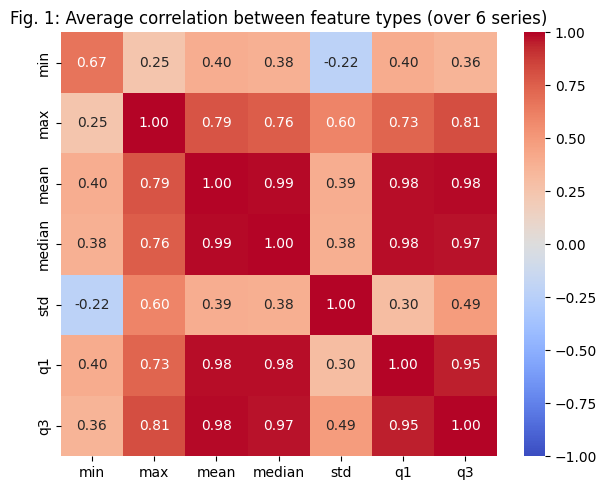

In [9]:
from scipy import stats

acts = np.array([i["activity"] for i in instances])
f_stats = {}
for f in ALL_FEATURES:
    vals = []
    for s in range(1, 7):
        groups = [feat_all.loc[acts == a, f"{f}_{s}"] for a in ACTIVITIES]
        F = stats.f_oneway(*groups).statistic
        vals.append(F)
    f_stats[f] = vals
f_df = pd.DataFrame(f_stats, index=[f"series {s}" for s in range(1, 7)]).T
f_df["mean F (ignoring NaN)"] = f_df.mean(axis=1)
display(f_df.round(1).sort_values("mean F (ignoring NaN)", ascending=False))

# average correlation between feature types (over the 6 series)
corr = np.zeros((len(ALL_FEATURES), len(ALL_FEATURES)))
for s in range(1, 7):
    c = feat_all[[f"{f}_{s}" for f in ALL_FEATURES]].corr().fillna(0).values
    corr += c / 6
plt.figure(figsize=(6, 5))
sns.heatmap(pd.DataFrame(corr, index=ALL_FEATURES, columns=ALL_FEATURES), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Fig. 1: Average correlation between feature types (over 6 series)")
plt.tight_layout(); plt.show()

**Answer 1(c)iv — choice of the three most important features: `mean`, `std` and `q3` (3rd quartile).**

* The location features (**mean, q3, median**) have by far the largest F-statistics, so they separate the
  activities best. Mean, median and q3 are strongly correlated (Fig. 1), so taking all three would
  mostly add redundant information. We keep **mean**, and add **q3**, which also describes the upper part
  of the distribution of the signal and has the 2nd largest average F.
* **std** has the largest F among the dispersion features and is much less correlated with the location
  features, so it adds new information (how much the signal fluctuates — e.g. walking/cycling vs.
  lying/bending).
* **min** is a poor choice: for the variance series (2 and 4) it is always 0 (zero standard deviation,
  see the bootstrap table above, and F is undefined), and **max** has small F values (it is very sensitive
  to single spikes).

In [10]:
SELECTED = ["mean", "std", "q3"]
print("Selected features:", SELECTED)

Selected features: ['mean', 'std', 'q3']


# 2. Time Series Classification Part 2: Binary and Multiclass Classification

## 2(a) Binary Classification Using Logistic Regression

### 2(a)i Scatter plots of the selected features of time series 1, 2 and 6 (training set)

Training set: bending = 9 , other = 60
Test set:     bending = 4 , other = 15


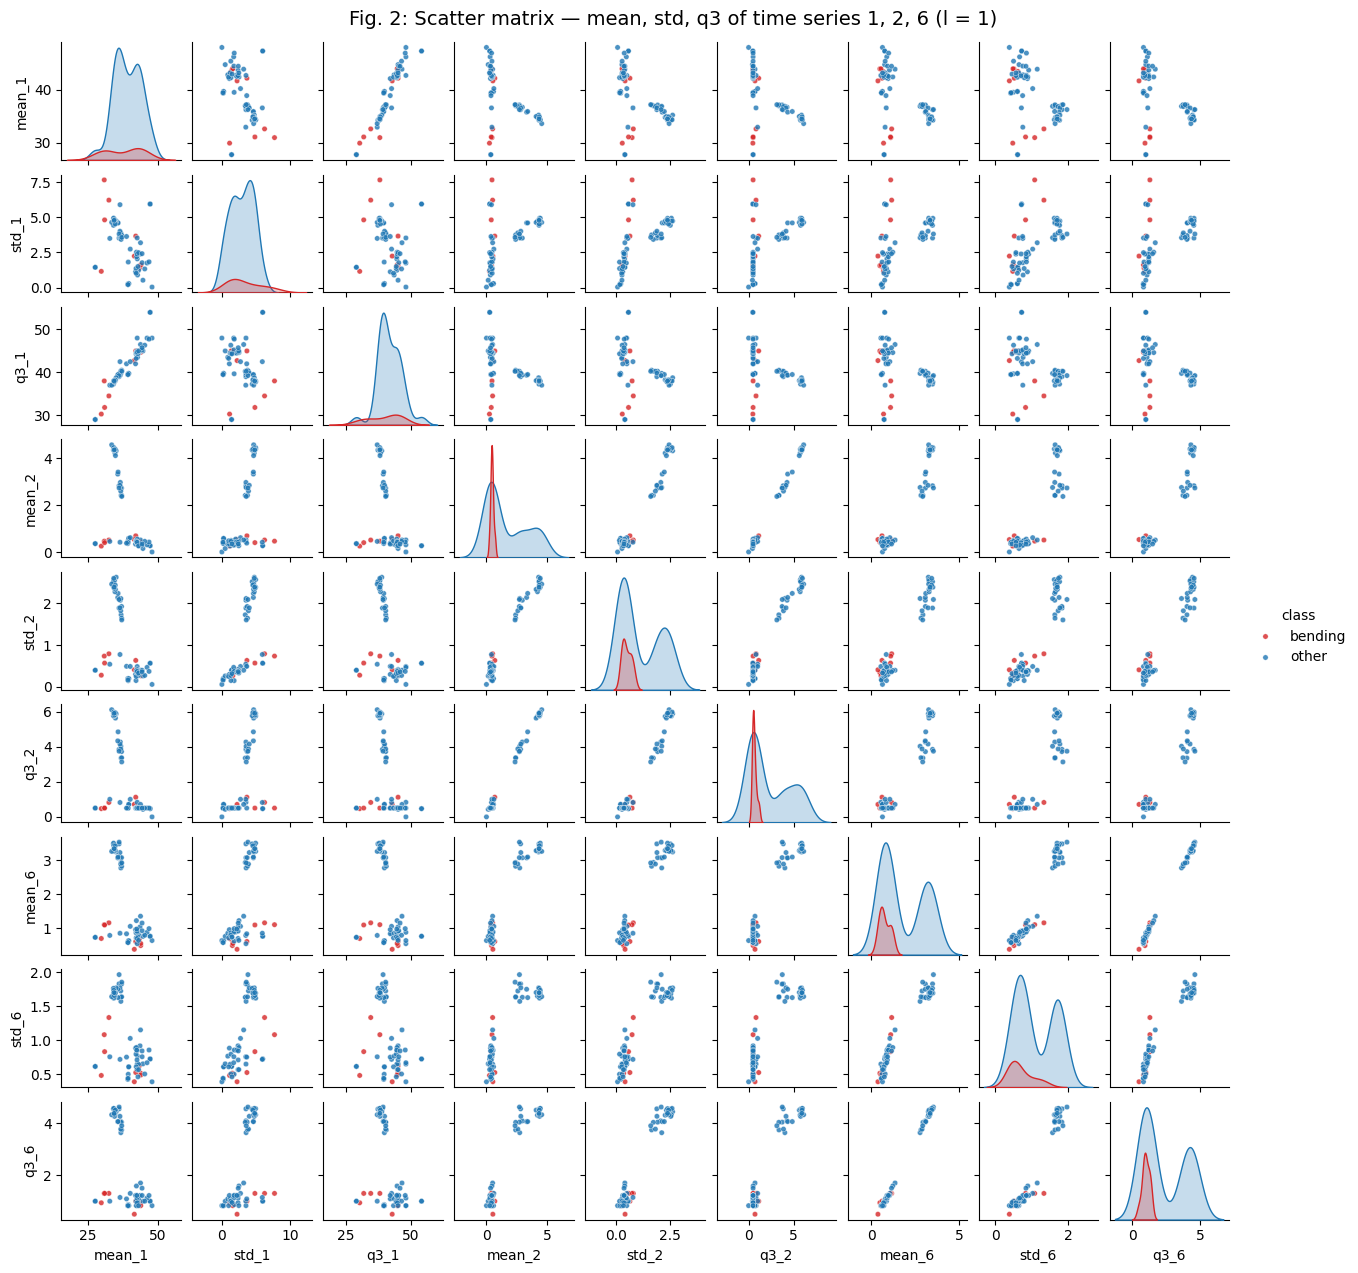

In [11]:
y_train_act = np.array([i["activity"] for i in train_inst])
y_test_act = np.array([i["activity"] for i in test_inst])
y_train_bin = np.isin(y_train_act, ["bending1", "bending2"]).astype(int)   # 1 = bending
y_test_bin = np.isin(y_test_act, ["bending1", "bending2"]).astype(int)
print("Training set: bending =", y_train_bin.sum(), ", other =", (1 - y_train_bin).sum())
print("Test set:     bending =", y_test_bin.sum(), ", other =", (1 - y_test_bin).sum())


def scatter_matrix(l, series=(1, 2, 6), title=""):
    X = extract_features(train_inst, l=l, features=SELECTED)
    cols = [f"{f}_{p * 6 + s}" for p in range(l) for s in series for f in SELECTED]
    df = X[cols].copy()
    df["class"] = np.where(y_train_bin == 1, "bending", "other")
    g = sns.pairplot(df, hue="class", palette={"bending": "tab:red", "other": "tab:blue"},
                     height=1.4 if l == 1 else 1.0, plot_kws={"s": 15, "alpha": 0.8}, corner=False)
    g.figure.suptitle(title, y=1.01, fontsize=14)
    plt.show()


scatter_matrix(1, title="Fig. 2: Scatter matrix — mean, std, q3 of time series 1, 2, 6 (l = 1)")

### 2(a)ii Break each series into two halves (l = 2) and repeat

Features `<f>_1`, `<f>_2`, `<f>_6` are from the first halves of series 1, 2, 6, and `<f>_7`, `<f>_8`, `<f>_12`
are from the second halves.

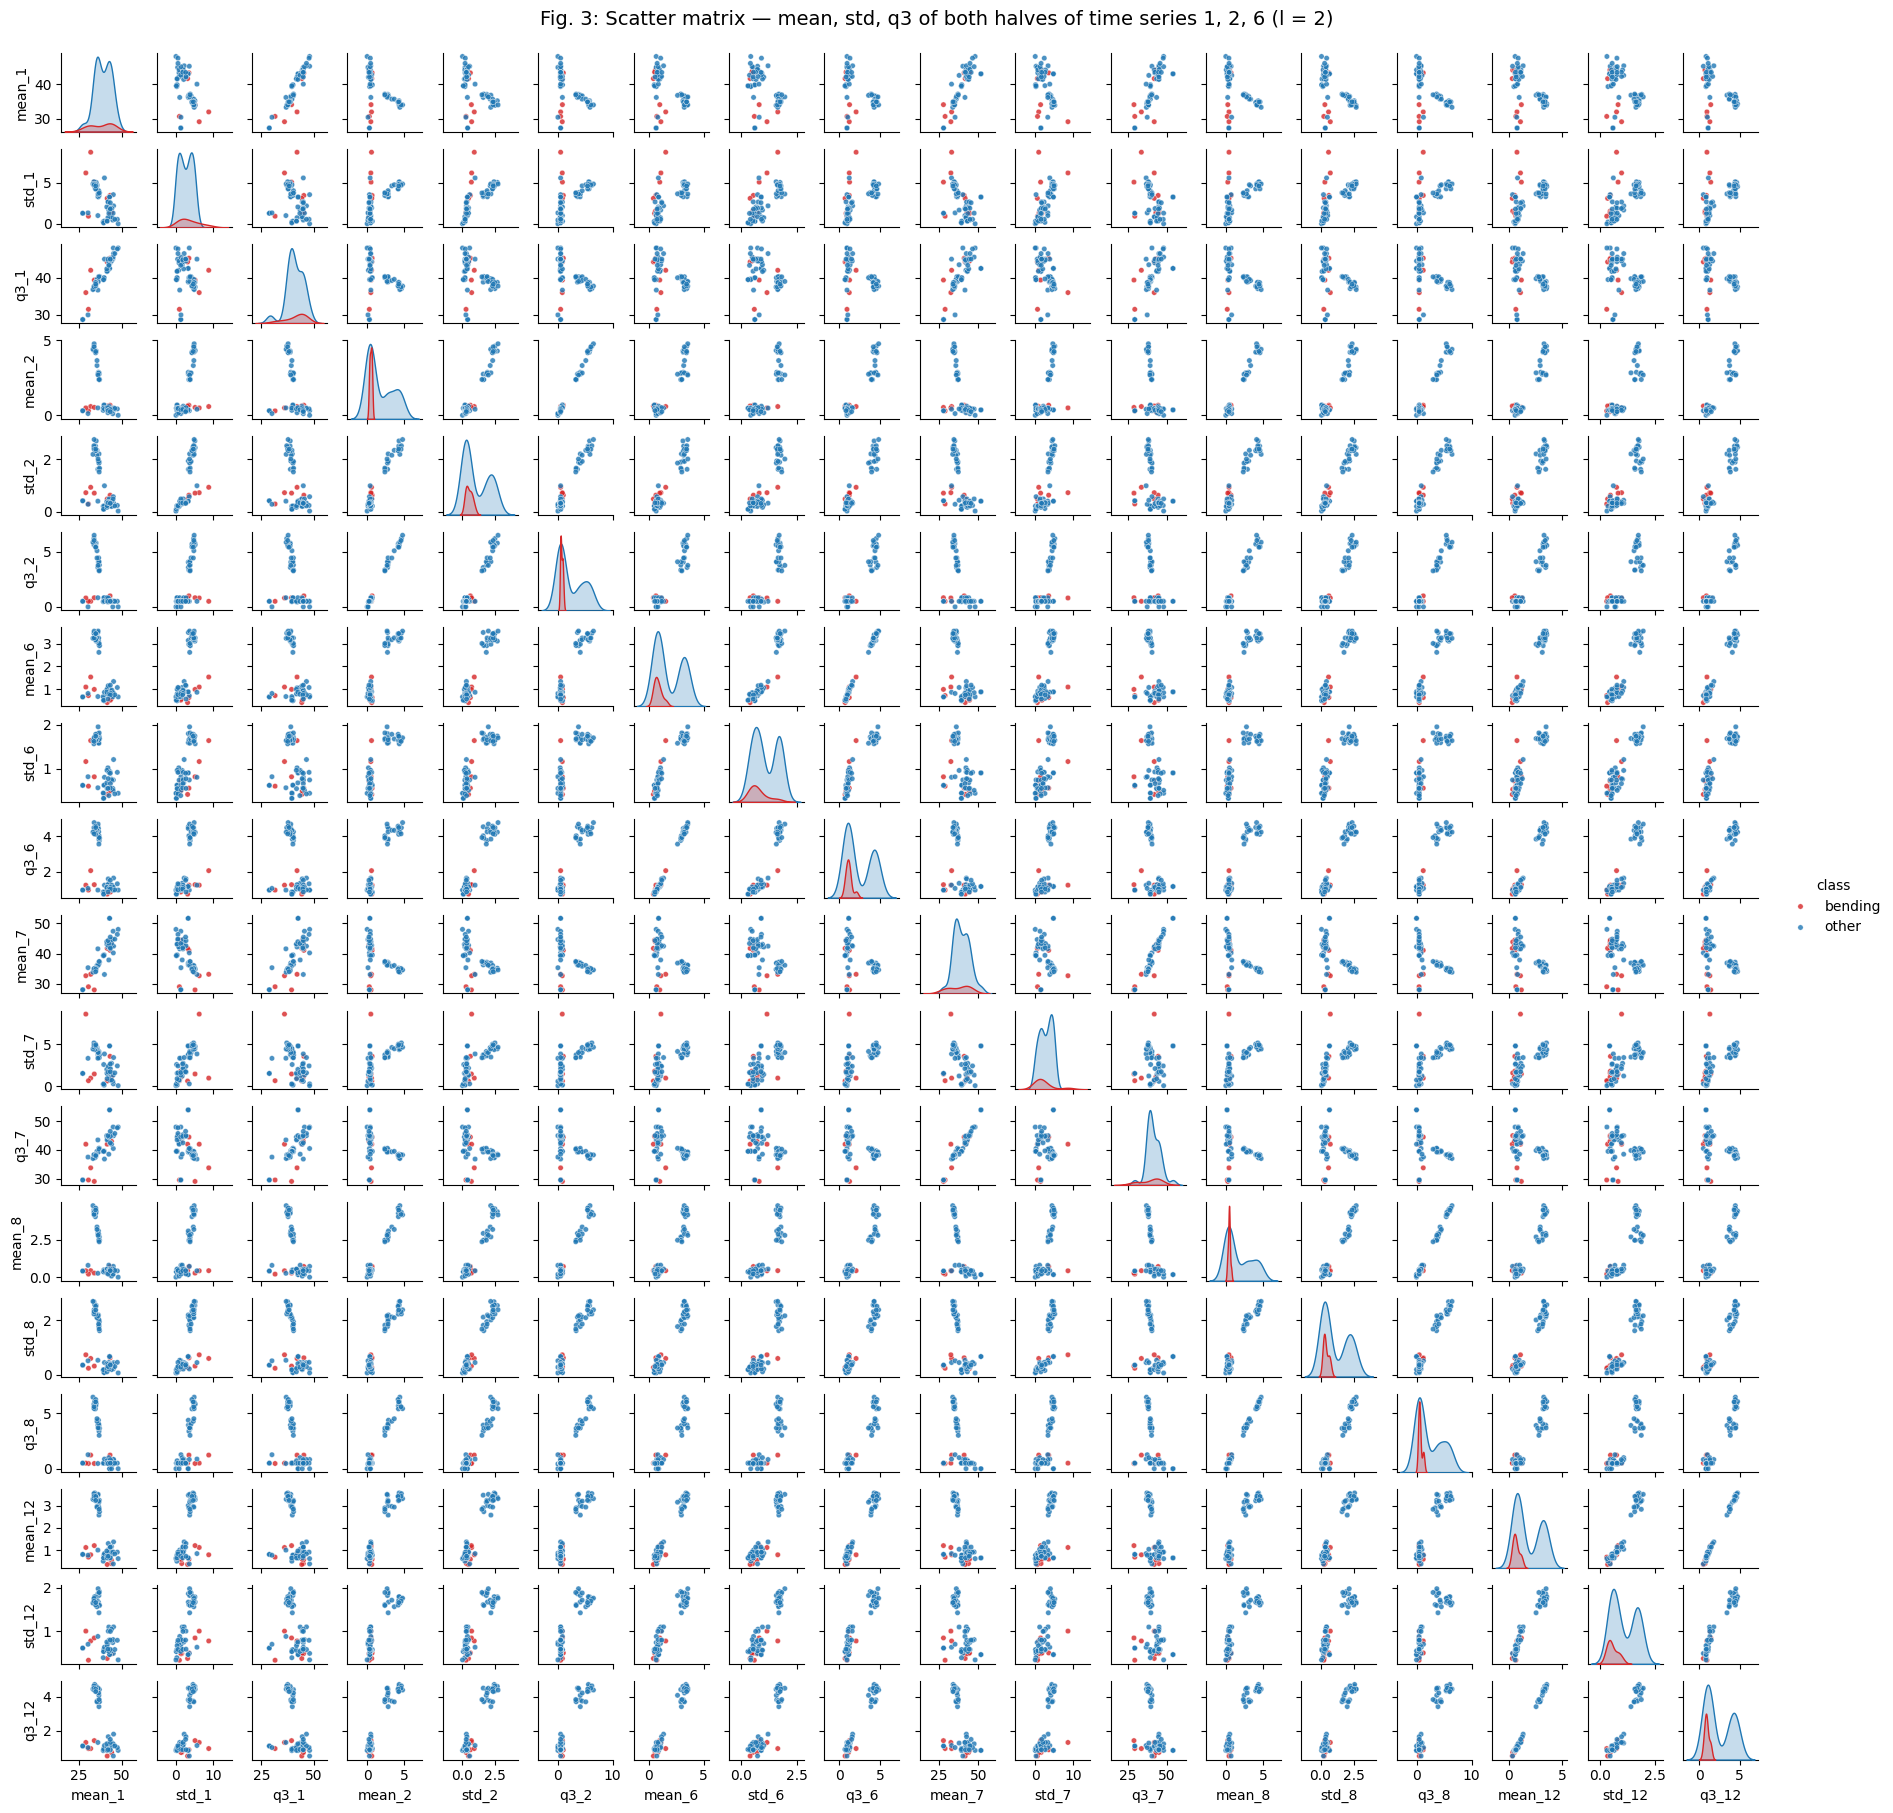

In [12]:
scatter_matrix(2, title="Fig. 3: Scatter matrix — mean, std, q3 of both halves of time series 1, 2, 6 (l = 2)")

**Answer 2(a)ii.** The scatter plots of the two halves look very similar to each other and to those of
2(a)i: for every feature, the first-half version (series 1, 2, 6) and the second-half version (series
7, 8, 12) are strongly correlated and the bending points fall in the same regions. Bending instances
are again concentrated at low values of `mean`/`q3` of series 2 and 6 (and 8, 12), but they overlap with
the low-variance "other" activities (sitting, standing, lying) in most single plots. So there is no
considerable difference: splitting into two halves mostly duplicates the information (the signals are
roughly stationary within 2 minutes); it only adds a little within-instance variability.

### 2(a)iii Choosing (l, p) with 5-fold cross-validation and Recursive Feature Elimination

**The right way vs. the wrong way of cross-validation.**
The feature selection (RFE, or p-value based pruning) is part of the model-fitting procedure, so it must
be **repeated inside every fold, using only that fold's training part**:

* **Wrong way:** run RFE / compute p-values on the *whole* training set, pick the p "best" features, and
  only then cross-validate a logistic regression on those features. The validation folds have already
  been used to choose the features, so the CV error is optimistically biased (information leakage),
  especially here where we have many features (up to 18·20 = 360) and only 69 instances.
* **Right way:** for every candidate l, build the features; split into 5 folds; for every fold, fit the
  standardisation, the RFE ranking and the logistic regression **on the 4 training folds only**, and
  evaluate on the held-out fold. The CV score of the pair (l, p) is the average over folds. The
  final model is then refit on the full training set with the chosen (l, p).

**Stratified cross-validation.** Only 9 of the 69 training instances are bending (≈ 13%). With plain
K-fold
some folds might contain no (or almost no) bending instances. Stratified K-fold makes each fold keep
approximately the same class proportions as the whole data set, so we use `StratifiedKFold`.

Implementation details:
* features = `mean`, `std`, `q3` (1(c)iv) of all 6 series ⇒ 18·l features;
* logistic regression without (effective) regularisation: `C = 1e10`, with `max_iter` limited as
  footnote 5 suggests (the classes are close to separable);
* RFE with `step = 1` eliminates one feature at a time; since the elimination path is nested, fitting
  RFE once down to 1 feature gives the RFE solution for every p (the top-p features by RFE ranking), which
  is identical to running `RFE(n_features_to_select=p)` for every p;
* p ∈ {1, …, min(18·l, 20)}; l ∈ {1, …, 20}.

Best (l, p) = (10, 2),  CV accuracy = 0.9857
Top 10 pairs:


,l,p,cv_accuracy
179,10,2,0.985714
383,20,6,0.985714
386,20,9,0.985714
38,3,1,0.971429
103,6,6,0.971429
124,7,7,0.971429
125,7,8,0.971429
145,8,8,0.971429
146,8,9,0.971429
147,8,10,0.971429


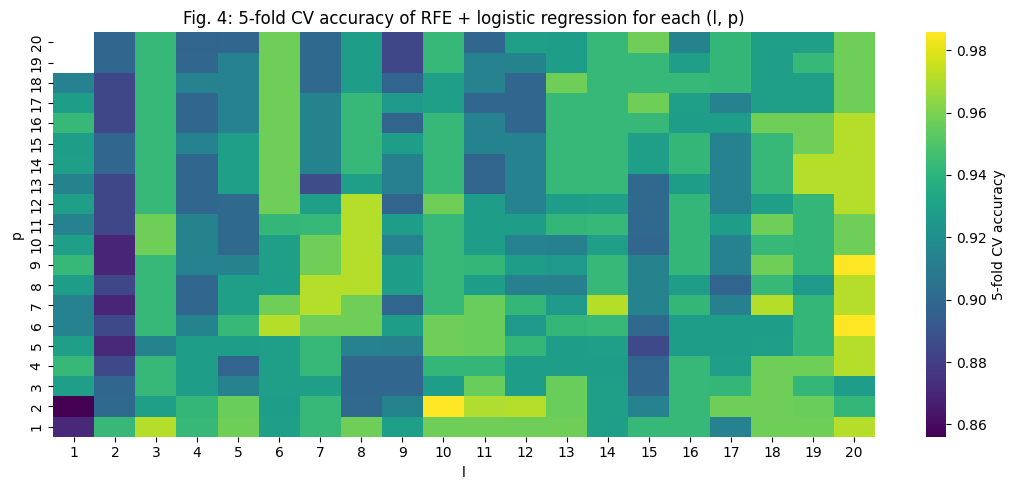

In [13]:
L_VALUES = list(range(1, 21))
P_MAX = 20
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# cache the features for every l
X_train_l = {l: extract_features(train_inst, l=l, features=SELECTED) for l in L_VALUES}
X_test_l = {l: extract_features(test_inst, l=l, features=SELECTED) for l in L_VALUES}


def plain_lr():
    # (almost) unregularised logistic regression, stopped early to avoid instability
    return LogisticRegression(C=1e10, solver="lbfgs", max_iter=200)


cv_rows = []
for l in L_VALUES:
    X = X_train_l[l].values
    n_feat = X.shape[1]
    p_range = range(1, min(n_feat, P_MAX) + 1)
    fold_acc = {p: [] for p in p_range}
    for tr, va in skf.split(X, y_train_bin):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        ranking = RFE(plain_lr(), n_features_to_select=1, step=1).fit(Xtr, y_train_bin[tr]).ranking_
        for p in p_range:
            cols = ranking <= p
            m = plain_lr().fit(Xtr[:, cols], y_train_bin[tr])
            fold_acc[p].append(accuracy_score(y_train_bin[va], m.predict(Xva[:, cols])))
    for p in p_range:
        cv_rows.append({"l": l, "p": p, "cv_accuracy": np.mean(fold_acc[p])})

cv_rfe = pd.DataFrame(cv_rows)
best_rfe = cv_rfe.sort_values(["cv_accuracy", "l", "p"], ascending=[False, True, True]).iloc[0]
best_l, best_p = int(best_rfe.l), int(best_rfe.p)
print(f"Best (l, p) = ({best_l}, {best_p}),  CV accuracy = {best_rfe.cv_accuracy:.4f}")
print("Top 10 pairs:")
display(cv_rfe.sort_values(["cv_accuracy", "l", "p"], ascending=[False, True, True]).head(10))

plt.figure(figsize=(11, 5))
sns.heatmap(cv_rfe.pivot(index="p", columns="l", values="cv_accuracy"), cmap="viridis", annot=False,
            cbar_kws={"label": "5-fold CV accuracy"})
plt.title("Fig. 4: 5-fold CV accuracy of RFE + logistic regression for each (l, p)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

Ties are broken in favour of the simplest model (smallest l, then smallest p).

**p-values.** The cell below also shows the p-value approach: for the chosen l, fit a logistic regression on
all features with `statsmodels` and look at the p-values; and fit the final model on the RFE-selected
features.

In [14]:
# Final model with (best_l, best_p) refit on the full training set
Xtr_full = X_train_l[best_l]
Xte_full = X_test_l[best_l]
scaler_rfe = StandardScaler().fit(Xtr_full)
Xtr_s = pd.DataFrame(scaler_rfe.transform(Xtr_full), columns=Xtr_full.columns)
Xte_s = pd.DataFrame(scaler_rfe.transform(Xte_full), columns=Xte_full.columns)

rfe_final = RFE(plain_lr(), n_features_to_select=best_p, step=1).fit(Xtr_s, y_train_bin)
sel_cols = list(Xtr_s.columns[rfe_final.support_])
print("Selected features:", sel_cols)
for c in sel_cols:
    print(f"   {c:>8s} = {describe(c, best_l)}")

lr_final = plain_lr().fit(Xtr_s[sel_cols], y_train_bin)

Selected features: ['mean_11', 'q3_37']
    mean_11 = mean of avg_rss23, part 2 of 10
      q3_37 = q3 of avg_rss12, part 7 of 10


### 2(a)iv Confusion matrix, ROC and AUC on the training data; β's and p-values

Training accuracy: 1.0
[[60  0]
 [ 0  9]]


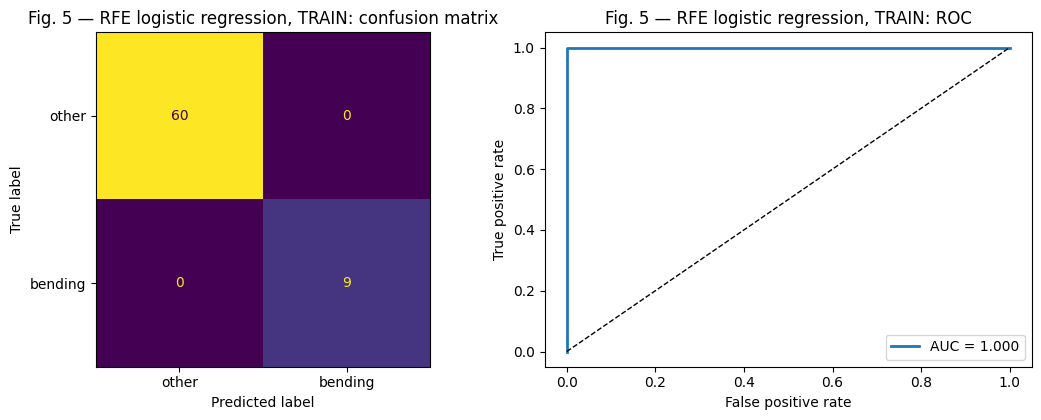

,beta (sklearn),beta (statsmodels),std err,z,p-value
const,-251.1296,-628.7337,114170.3392,-0.0055,0.9956
mean_11,226.8791,563.6273,100942.1492,0.0056,0.9955
q3_37,-111.1736,-276.9300,49626.7515,-0.0056,0.9955


In [15]:
def logit_pvalues(X, y):
    """Fit an unpenalised logistic regression with statsmodels and return coefficients + p-values."""
    Xc = sm.add_constant(X, has_constant="add")
    try:
        res = sm.Logit(y, Xc).fit(disp=0, maxiter=200, method="bfgs")
        out = pd.DataFrame({"beta (statsmodels)": res.params, "std err": res.bse,
                            "z": res.tvalues, "p-value": res.pvalues})
    except Exception as e:  # perfect separation etc.
        print("statsmodels could not fit the model:", e)
        out = None
    return out


def plot_cm_roc(y_true, scores, y_pred, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]),
                           display_labels=["other", "bending"]).plot(ax=ax[0], colorbar=False)
    ax[0].set_title(f"{title}: confusion matrix")
    fpr, tpr, _ = roc_curve(y_true, scores)
    a = roc_auc_score(y_true, scores)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {a:.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    ax[1].set_title(f"{title}: ROC"); ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.show()
    return a


train_pred = lr_final.predict(Xtr_s[sel_cols])
train_score = lr_final.predict_proba(Xtr_s[sel_cols])[:, 1]
print("Training accuracy:", accuracy_score(y_train_bin, train_pred))
print(confusion_matrix(y_train_bin, train_pred))
auc_train = plot_cm_roc(y_train_bin, train_score, train_pred, "Fig. 5 — RFE logistic regression, TRAIN")

coef_tbl = pd.DataFrame({"beta (sklearn)": np.r_[lr_final.intercept_, lr_final.coef_.ravel()]},
                        index=["const"] + sel_cols)
pv = logit_pvalues(Xtr_s[sel_cols], y_train_bin)
if pv is not None:
    coef_tbl = coef_tbl.join(pv)
display(coef_tbl.round(4))

**Answer 2(a)iv.**
* Chosen by 5-fold stratified CV: **l = 10, p = 2** (CV accuracy 0.9857). RFE selects
  `mean_11` (mean of `avg_rss23` in part 2 of 10) and `q3_37` (3rd quartile of `avg_rss12` in part 7 of 10).
* **Training confusion matrix:** all 60 "other" and all 9 "bending" instances are correctly classified
  (accuracy = 1.0); **training AUC = 1.0** (Fig. 5).
* The β's (on standardised features) and their p-values are shown in the table above. The coefficients are
  very large (|β| in the hundreds) and the standard errors are enormous, so all p-values are ≈ 1. This is not
  because the features are useless: the training data are **perfectly separated**, so the maximum-likelihood
  estimates do not exist (they diverge to ±∞), and the Wald standard errors / p-values are meaningless
  (see 2(a)vi). The sklearn and statsmodels estimates differ only because each stops at a different point
  of a diverging optimisation.

### 2(a)v Test the classifier on the test set
The test series are split into the same `l` parts, the features are extracted from the test set and
standardised with the scaler fitted on the training set.

Test accuracy = 1.0000   vs   5-fold CV accuracy = 0.9857
[[15  0]
 [ 0  4]]


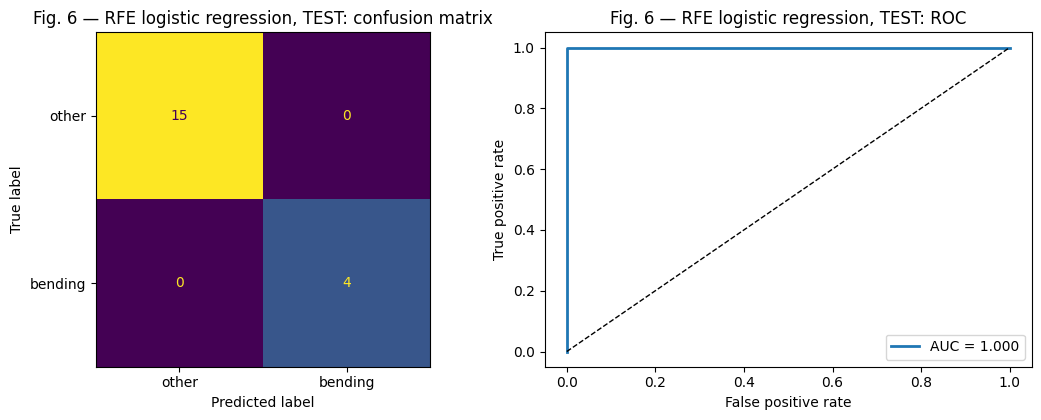

In [16]:
test_pred = lr_final.predict(Xte_s[sel_cols])
test_score = lr_final.predict_proba(Xte_s[sel_cols])[:, 1]
test_acc_rfe = accuracy_score(y_test_bin, test_pred)
print(f"Test accuracy = {test_acc_rfe:.4f}   vs   5-fold CV accuracy = {best_rfe.cv_accuracy:.4f}")
print(confusion_matrix(y_test_bin, test_pred))
auc_test = plot_cm_roc(y_test_bin, test_score, test_pred, "Fig. 6 — RFE logistic regression, TEST")

**Answer 2(a)v.** Test accuracy = **1.0** (15/15 other and 4/4 bending correctly classified, test AUC = 1.0),
compared with a 5-fold CV accuracy of **0.9857**. The two are very close; the test accuracy is even a bit
higher, which is within the noise of a test set of only 19 instances (one mistake would change the
accuracy by 0.053). CV accuracy is a reasonable estimate of the test performance.

### 2(a)vi Are the classes well separated (instability of logistic regression)?

In [17]:
# Check separation: how far are the fitted coefficients from 0 and do the predicted probabilities
# saturate at 0/1? Also fit the same model with many more iterations and compare the coefficients.
lr_long = LogisticRegression(C=1e10, solver="lbfgs", max_iter=100000).fit(Xtr_s[sel_cols], y_train_bin)
print("Coefficients, max_iter=200   :", np.round(lr_final.coef_.ravel(), 2))
print("Coefficients, max_iter=100000:", np.round(lr_long.coef_.ravel(), 2))
print("Min / max fitted probability for bending instances:",
      train_score[y_train_bin == 1].min().round(4), train_score[y_train_bin == 1].max().round(4))
print("Min / max fitted probability for other instances:  ",
      train_score[y_train_bin == 0].min().round(4), train_score[y_train_bin == 0].max().round(4))

Coefficients, max_iter=200   : [ 226.88 -111.17]
Coefficients, max_iter=100000: [ 226.88 -111.17]
Min / max fitted probability for bending instances: 0.9926 1.0
Min / max fitted probability for other instances:   0.0 0.0067


**Answer 2(a)vi.** **Yes.** The classes are (perfectly) linearly separable in the selected feature space:
training accuracy is 100%, the fitted probabilities are ≥ 0.99 for every bending instance and ≤ 0.007 for every
other instance, and the coefficients are huge with gigantic standard errors (p-values ≈ 1). For separable data
the logistic-regression likelihood keeps increasing as ‖β‖ → ∞, so the MLE does not exist and the
parameter estimates are unstable — their values depend only on when the optimiser stops (`max_iter`,
tolerance, or the tiny residual penalty C = 1e10). That is exactly why the algorithm was stopped early as
suggested in footnote 5, and why the p-values cannot be trusted here. (The classifier itself is still
excellent; only the coefficient values / inference are unstable.)

### 2(a)vii Class imbalance and case-control sampling

In [18]:
pi_pop = y_train_bin.mean()          # prevalence of bending in the training data
print(f"Bending: {y_train_bin.sum()} / {len(y_train_bin)}  (prevalence = {pi_pop:.3f})")

Bending: 9 / 69  (prevalence = 0.130)


**Answer 2(a)vii.** **Yes, the classes are imbalanced**: only 9 of the 69 training instances (13%) and 4 of the 19
test instances are bending.

**Case-control sampling.** We keep all 9 cases (bending) and randomly draw the same number (9) of controls
(other activities), so the sample prevalence is π̃ = 0.5. Fitting a logistic regression on this sample gives
consistent slopes β₁,…,β_p, but the intercept is biased. With the true (population) prevalence
π = 9/69, the intercept is corrected as (ESL §4.4.2 / ISLR):

$$\hat\beta_0 = \hat\beta_0^{*} + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}.$$

The same (l, p) = (10, 2) and the same two features as in 2(a)iii are used.

Intercept fitted on case-control sample: -15.1389  -> adjusted intercept: -17.0360


,"beta (case-control, adjusted)"
const,-17.0360
mean_11,19.8721
q3_37,-9.3501


TRAIN (all 69): accuracy = 0.9855


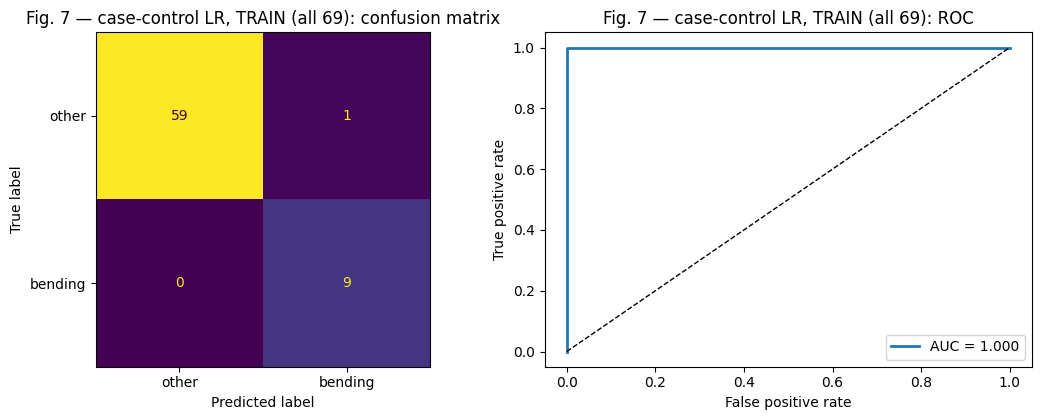

TEST: accuracy = 1.0000


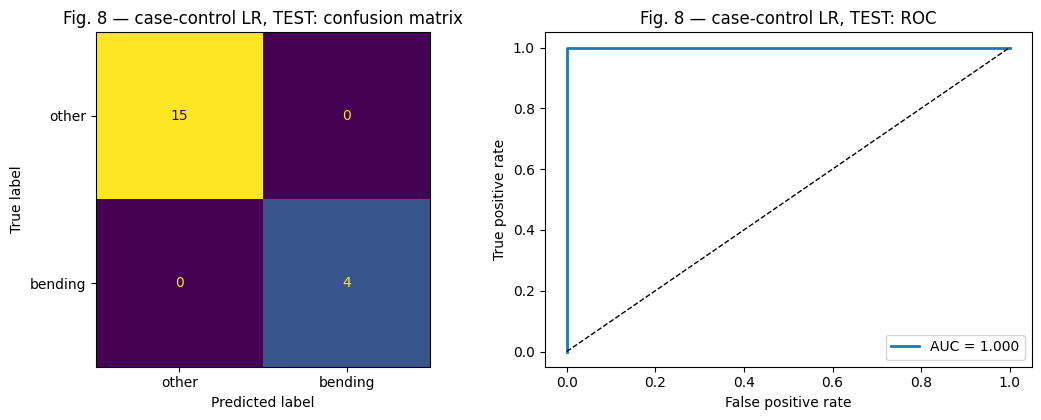

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.where(y_train_bin == 1)[0]
ctrl_idx = rng.choice(np.where(y_train_bin == 0)[0], size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, ctrl_idx]
pi_sample = y_train_bin[cc_idx].mean()   # = 0.5

lr_cc = plain_lr().fit(Xtr_s.iloc[cc_idx][sel_cols], y_train_bin[cc_idx])
b0_star = lr_cc.intercept_[0]
b0_adj = b0_star + np.log(pi_pop / (1 - pi_pop)) - np.log(pi_sample / (1 - pi_sample))
lr_cc.intercept_ = np.array([b0_adj])   # adjusted intercept, slopes unchanged
print(f"Intercept fitted on case-control sample: {b0_star:.4f}  -> adjusted intercept: {b0_adj:.4f}")
display(pd.DataFrame({"beta (case-control, adjusted)": np.r_[lr_cc.intercept_, lr_cc.coef_.ravel()]},
                     index=["const"] + sel_cols).round(4))

for name, Xs, yy, fig in [("TRAIN (all 69)", Xtr_s, y_train_bin, "Fig. 7"), ("TEST", Xte_s, y_test_bin, "Fig. 8")]:
    pred = lr_cc.predict(Xs[sel_cols]); sc = lr_cc.predict_proba(Xs[sel_cols])[:, 1]
    print(f"{name}: accuracy = {accuracy_score(yy, pred):.4f}")
    plot_cm_roc(yy, sc, pred, f"{fig} — case-control LR, {name}")

The adjusted case-control model classifies all 9 bending instances and 59 of 60 other training instances
correctly (training accuracy 0.9855, training AUC = 1.0, Fig. 7), and all 19 test instances correctly
(test accuracy 1.0, test AUC = 1.0, Fig. 8). Because the 9+9 sample is again perfectly separable, the
coefficients are still not well determined (they are much smaller than before only because the optimiser
stopped at a different point), but the decision rule is practically the same as the model trained on the
full training set.

## 2(b) Binary Classification Using L1-penalized logistic regression

### 2(b)i Cross-validate l and the L1 budget C (λ = 1/C)
Features are standardised inside a pipeline, so the scaler is refit in every fold (right way of CV).
`liblinear` is used as the solver, as recommended.

Best l = 12, best C = 3.162 (lambda = 0.3162), CV accuracy = 0.9857


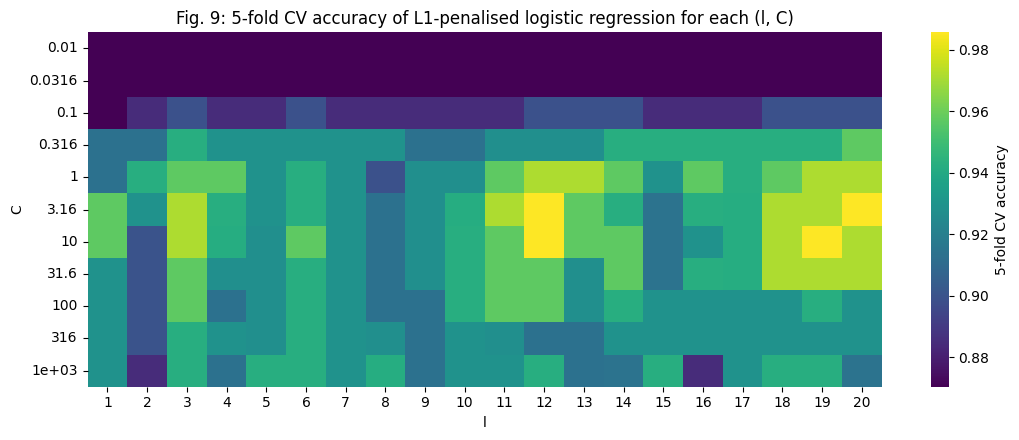

In [20]:
C_GRID = np.logspace(-2, 3, 11)


def l1_binary(C):
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", l1_logreg(C, "liblinear", max_iter=5000))])


cv_l1_rows = []
for l in L_VALUES:
    for C in C_GRID:
        s = cross_val_score(l1_binary(C), X_train_l[l], y_train_bin, cv=skf, scoring="accuracy")
        cv_l1_rows.append({"l": l, "C": C, "cv_accuracy": s.mean()})
cv_l1 = pd.DataFrame(cv_l1_rows)
# tie-break: smallest l, then smallest C (strongest penalty, simplest model)
best_l1 = cv_l1.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True]).iloc[0]
best_l_l1, best_C_l1 = int(best_l1.l), best_l1.C
print(f"Best l = {best_l_l1}, best C = {best_C_l1:.4g} (lambda = {1 / best_C_l1:.4g}), "
      f"CV accuracy = {best_l1.cv_accuracy:.4f}")

plt.figure(figsize=(11, 4.5))
sns.heatmap(cv_l1.pivot(index="C", columns="l", values="cv_accuracy").rename(index=lambda c: f"{c:.3g}"),
            cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("Fig. 9: 5-fold CV accuracy of L1-penalised logistic regression for each (l, C)")
plt.tight_layout(); plt.show()

Non-zero coefficients: 11 of 216


,beta,meaning
mean_11,3.4200,"mean of avg_rss23, part 2 of 12"
std_15,0.2098,"std of avg_rss13, part 3 of 12"
std_33,-0.1267,"std of avg_rss13, part 6 of 12"
std_37,-0.3568,"std of avg_rss12, part 7 of 12"
q3_37,-0.7669,"q3 of avg_rss12, part 7 of 12"
mean_52,-0.2877,"mean of var_rss13, part 9 of 12"
q3_52,-0.0728,"q3 of var_rss13, part 9 of 12"
std_57,-0.1108,"std of avg_rss13, part 10 of 12"
mean_65,0.6298,"mean of avg_rss23, part 11 of 12"
std_65,-0.0899,"std of avg_rss23, part 11 of 12"


TRAIN: accuracy = 1.0000


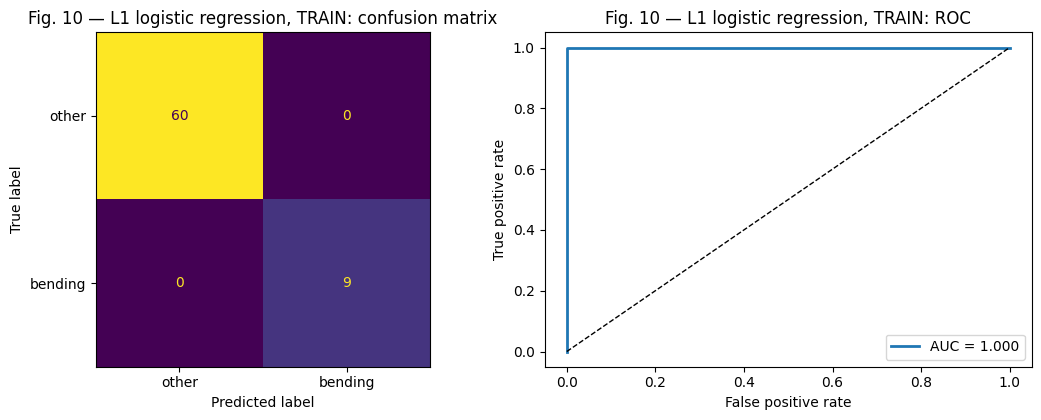

TEST: accuracy = 0.9474


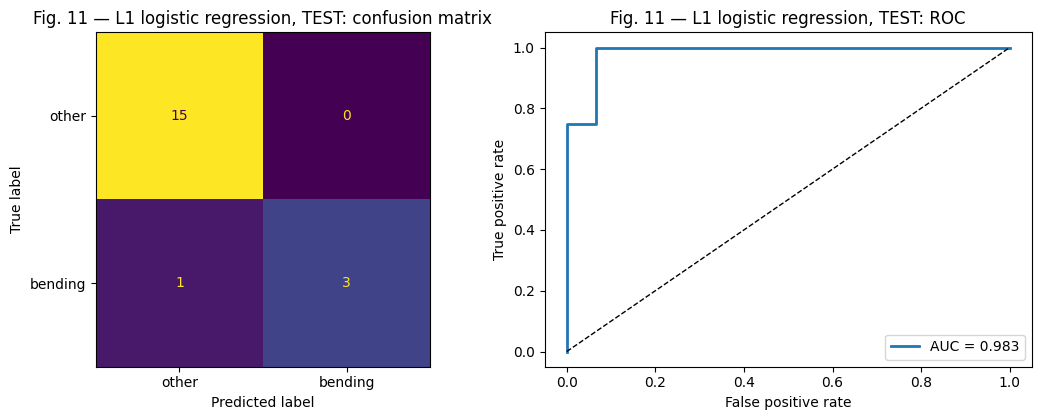

In [21]:
l1_model = l1_binary(best_C_l1).fit(X_train_l[best_l_l1], y_train_bin)
coefs = pd.Series(l1_model.named_steps["lr"].coef_.ravel(), index=X_train_l[best_l_l1].columns)
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")
nz = coefs[coefs != 0].to_frame("beta")
nz["meaning"] = [describe(c, best_l_l1) for c in nz.index]
display(nz.round(4))

for name, X, yy, fig in [("TRAIN", X_train_l[best_l_l1], y_train_bin, "Fig. 10"),
                         ("TEST", X_test_l[best_l_l1], y_test_bin, "Fig. 11")]:
    pred = l1_model.predict(X); sc = l1_model.predict_proba(X)[:, 1]
    print(f"{name}: accuracy = {accuracy_score(yy, pred):.4f}")
    plot_cm_roc(yy, sc, pred, f"{fig} — L1 logistic regression, {name}")
test_acc_l1 = accuracy_score(y_test_bin, l1_model.predict(X_test_l[best_l_l1]))

### 2(b)ii Compare L1-penalised regression with variable selection using p-values / RFE

In [22]:
pd.DataFrame({
    "method": ["RFE / p-value selection + LR", "L1-penalised LR"],
    "chosen l": [best_l, best_l_l1],
    "#features used": [best_p, int((coefs != 0).sum())],
    "CV accuracy": [best_rfe.cv_accuracy, best_l1.cv_accuracy],
    "test accuracy": [test_acc_rfe, test_acc_l1],
}).set_index("method").round(4)

,chosen l,#features used,CV accuracy,test accuracy
method,,,,
RFE / p-value selection + LR,10,2,0.9857,1.0000
L1-penalised LR,12,11,0.9857,0.9474


**Answer 2(b)ii.**
* **Performance:** Both methods reach the same 5-fold CV accuracy (0.9857). On the test set the
  RFE / p-value model is correct on all 19 instances, while the L1 model (l = 12, C ≈ 3.16, 11 non-zero
  coefficients out of 216) misclassifies 1 of 19 (accuracy 0.947). With such a small test set this one
  error is not a significant difference, so the two approaches perform about equally well here; the
  RFE model is sparser (2 features).
* **Stability:** the L1 model is better behaved — the penalty keeps the coefficients finite even though the
  classes are separable, while unpenalised logistic regression with p-value selection suffers from the
  divergence/instability described in 2(a)vi (its p-values are meaningless here).
* **Ease of implementation:** L1-penalised logistic regression is clearly **easier**: variable selection is
  built into a single fit, and only one tuning parameter (λ or C) has to be cross-validated together with l
  (one call to `cross_val_score` per pair). Variable selection with p-values / RFE needs a nested
  selection procedure inside every CV fold, an extra loop over p, and a separate statistical package for
  p-values, which in addition are unreliable for separable data.

## 2(c) Multi-class Classification (The Realistic Case)

### 2(c)i L1-penalised multinomial logistic regression
Same procedure as 2(b)i: cross-validate (l, C) with stratified 5-fold CV (scaler inside the pipeline),
now with all 7 activities as classes. The `saga` solver supports the L1 penalty with the multinomial
(softmax) loss.

Best l = 2, best C = 1000, CV accuracy = 0.9286


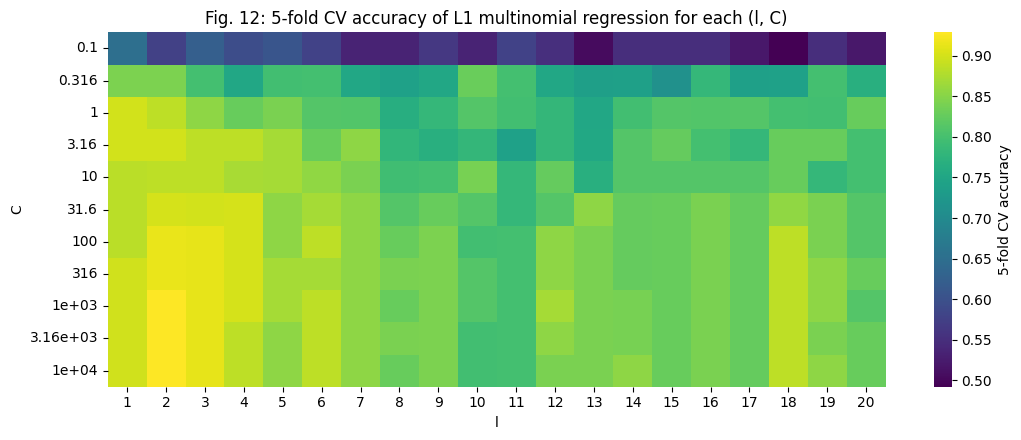

In [23]:
C_GRID_MC = np.logspace(-1, 4, 11)


def l1_multinomial(C):
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", l1_logreg(C, "saga", max_iter=5000, tol=1e-3))])


cv_mc_rows = []
for l in L_VALUES:
    for C in C_GRID_MC:
        s = cross_val_score(l1_multinomial(C), X_train_l[l], y_train_act, cv=skf, scoring="accuracy")
        cv_mc_rows.append({"l": l, "C": C, "cv_accuracy": s.mean()})
cv_mc = pd.DataFrame(cv_mc_rows)
best_mc = cv_mc.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True]).iloc[0]
best_l_mc, best_C_mc = int(best_mc.l), best_mc.C
print(f"Best l = {best_l_mc}, best C = {best_C_mc:.4g}, CV accuracy = {best_mc.cv_accuracy:.4f}")

plt.figure(figsize=(11, 4.5))
sns.heatmap(cv_mc.pivot(index="C", columns="l", values="cv_accuracy").rename(index=lambda c: f"{c:.3g}"),
            cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("Fig. 12: 5-fold CV accuracy of L1 multinomial regression for each (l, C)")
plt.tight_layout(); plt.show()

**Confusion matrix and ROC for multi-class problems.**
* The multi-class confusion matrix is a K×K table whose entry (i, j) counts the instances of true class i
  predicted as class j; the diagonal holds the correct predictions.
* ROC curves are defined for a binary decision, so for K classes one uses the **one-vs-rest** approach:
  for every class k, treat k as positive and all other classes as negative and draw the ROC curve using
  the predicted probability P(class = k | x). These can be summarised by a **macro-average** (average of the K
  per-class curves / AUCs, every class has equal weight) or a **micro-average** (pool all K·n binary decisions
  into one ROC curve; every instance has equal weight). (An alternative is the one-vs-one average AUC of
  Hand & Till, 2001.)

L1 multinomial LR: test accuracy = 0.8421,  test error = 0.1579
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19



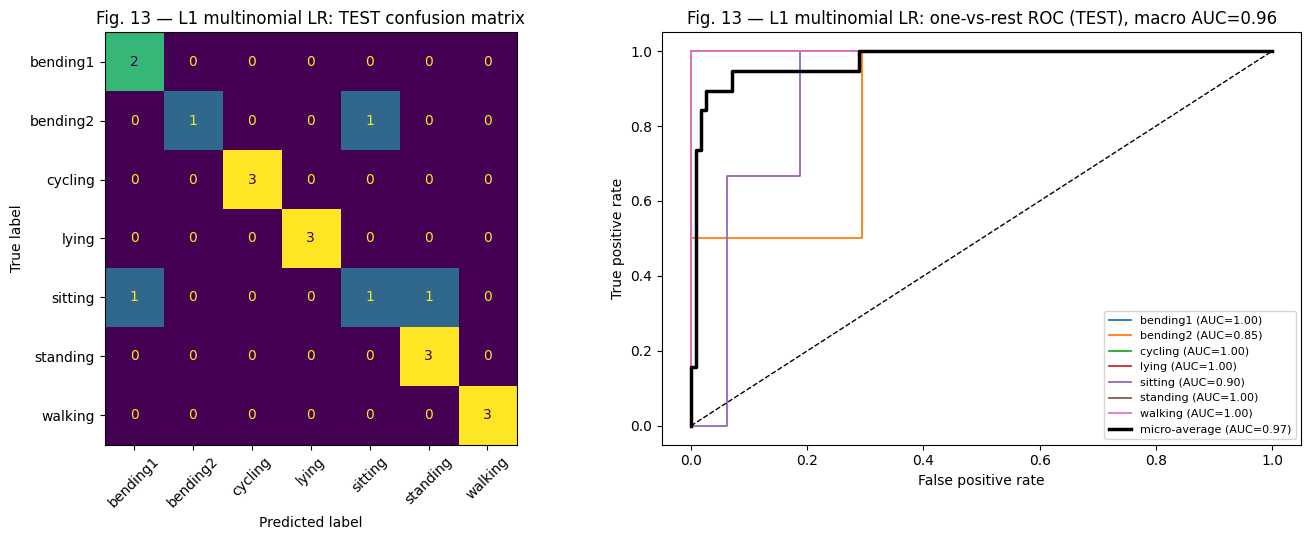

In [24]:
def multiclass_report(model, X_tr, X_te, title, fig_no):
    model.fit(X_tr, y_train_act)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)
    classes = model.classes_
    acc = accuracy_score(y_test_act, pred)
    print(f"{title}: test accuracy = {acc:.4f},  test error = {1 - acc:.4f}")
    print(classification_report(y_test_act, pred, zero_division=0))

    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay(confusion_matrix(y_test_act, pred, labels=classes),
                           display_labels=classes).plot(ax=ax[0], colorbar=False, xticks_rotation=45)
    ax[0].set_title(f"{fig_no} — {title}: TEST confusion matrix")

    Y = label_binarize(y_test_act, classes=classes)
    aucs = {}
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        aucs[c] = auc(fpr, tpr)
        ax[1].plot(fpr, tpr, lw=1.3, label=f"{c} (AUC={aucs[c]:.2f})")
    fpr_mi, tpr_mi, _ = roc_curve(Y.ravel(), proba.ravel())
    micro = auc(fpr_mi, tpr_mi)
    macro = roc_auc_score(Y, proba, average="macro")
    ax[1].plot(fpr_mi, tpr_mi, "k-", lw=2.5, label=f"micro-average (AUC={micro:.2f})")
    ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    ax[1].set_title(f"{fig_no} — {title}: one-vs-rest ROC (TEST), macro AUC={macro:.2f}")
    ax[1].legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()
    return acc, micro, macro


res_mc = multiclass_report(l1_multinomial(best_C_mc), X_train_l[best_l_mc], X_test_l[best_l_mc],
                           "L1 multinomial LR", "Fig. 13")

**Answer 2(c)i.** The best pair from stratified 5-fold CV is **l = 2, C = 1000** (weak penalty, CV accuracy 0.929).
On the test set the L1-penalised multinomial model gets 16/19 correct:
**test accuracy = 0.842, test error = 0.158**. The errors are one bending2 instance predicted as
sitting, one sitting predicted as bending1 and one sitting predicted as standing — i.e. confusions between
the static postures, which have similar signals. Cycling, lying, standing and walking are all classified
correctly. The one-vs-rest ROC curves give AUC = 1 for five classes, 0.90 for sitting and 0.85 for
bending2; micro-average AUC = 0.97, macro-average AUC = 0.96 (Fig. 13).

### 2(c)ii Naïve Bayes classifiers (Gaussian and Multinomial)
As in 2(c)i, l is chosen by stratified 5-fold CV.
* **Gaussian NB** models every feature within a class as a normal distribution.
* **Multinomial NB** models the features as (non-negative) counts/frequencies. Our features are continuous
  (and the standardised ones can be negative), so they are first rescaled to [0, 1] with a `MinMaxScaler`
  fitted inside each fold. Its smoothing parameter α is cross-validated as well.

Gaussian NB:    best l = 7, CV accuracy = 0.8703
Multinomial NB: best l = 2, alpha = 0.01, CV accuracy = 0.7967


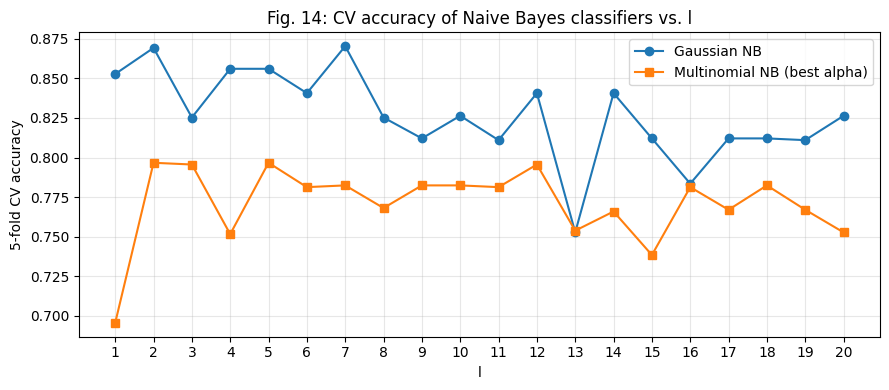

In [25]:
def gnb():
    return GaussianNB()


def mnb(alpha=1.0):
    return Pipeline([("scaler", MinMaxScaler(clip=True)), ("nb", MultinomialNB(alpha=alpha))])


cv_nb_rows = []
for l in L_VALUES:
    cv_nb_rows.append({"model": "Gaussian NB", "l": l, "alpha": np.nan,
                       "cv_accuracy": cross_val_score(gnb(), X_train_l[l], y_train_act, cv=skf).mean()})
    for a in [0.01, 0.1, 0.5, 1.0]:
        cv_nb_rows.append({"model": "Multinomial NB", "l": l, "alpha": a,
                           "cv_accuracy": cross_val_score(mnb(a), X_train_l[l], y_train_act, cv=skf).mean()})
cv_nb = pd.DataFrame(cv_nb_rows)

best_g = cv_nb[cv_nb.model == "Gaussian NB"].sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
best_m = cv_nb[cv_nb.model == "Multinomial NB"].sort_values(["cv_accuracy", "l", "alpha"],
                                                            ascending=[False, True, False]).iloc[0]
print(f"Gaussian NB:    best l = {int(best_g.l)}, CV accuracy = {best_g.cv_accuracy:.4f}")
print(f"Multinomial NB: best l = {int(best_m.l)}, alpha = {best_m.alpha}, CV accuracy = {best_m.cv_accuracy:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(L_VALUES, cv_nb[cv_nb.model == "Gaussian NB"].cv_accuracy, "o-", label="Gaussian NB")
plt.plot(L_VALUES, cv_nb[cv_nb.model == "Multinomial NB"].groupby("l").cv_accuracy.max(), "s-",
         label="Multinomial NB (best alpha)")
plt.xlabel("l"); plt.ylabel("5-fold CV accuracy"); plt.xticks(L_VALUES); plt.legend()
plt.title("Fig. 14: CV accuracy of Naive Bayes classifiers vs. l"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

Gaussian NB: test accuracy = 0.7895,  test error = 0.2105
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.40      0.67      0.50         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.79        19
   macro avg       0.87      0.79      0.80        19
weighted avg       0.85      0.79      0.80        19



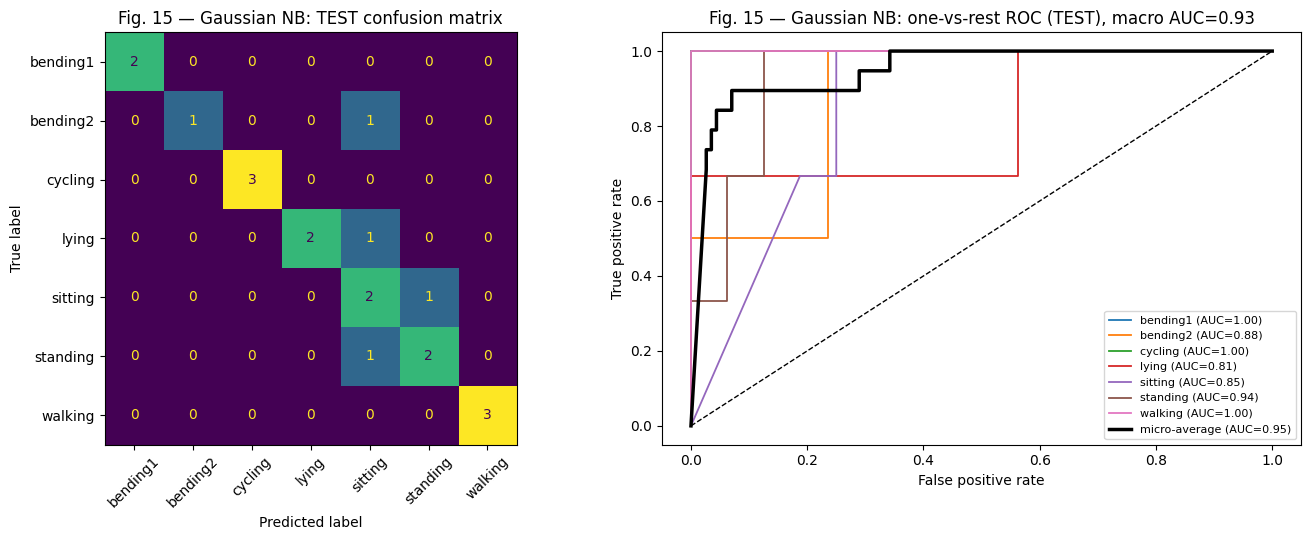

Multinomial NB: test accuracy = 0.7895,  test error = 0.2105
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       0.75      1.00      0.86         3
       lying       1.00      0.67      0.80         3
     sitting       0.50      0.67      0.57         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.79        19
   macro avg       0.85      0.79      0.79        19
weighted avg       0.83      0.79      0.79        19



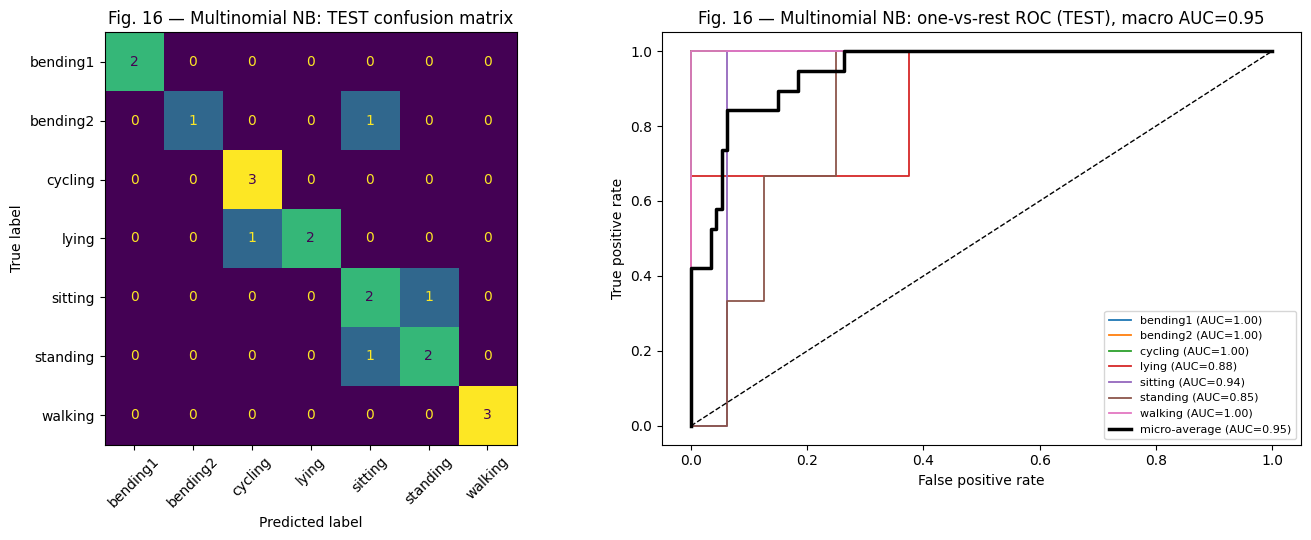

In [26]:
res_g = multiclass_report(gnb(), X_train_l[int(best_g.l)], X_test_l[int(best_g.l)], "Gaussian NB", "Fig. 15")
res_m = multiclass_report(mnb(best_m.alpha), X_train_l[int(best_m.l)], X_test_l[int(best_m.l)],
                          "Multinomial NB", "Fig. 16")

**Answer 2(c)ii.**
* **Gaussian NB** (best l = 7, CV accuracy 0.870): test accuracy 0.789, **test error = 0.211**,
  micro/macro AUC = 0.95/0.93.
* **Multinomial NB** (best l = 2, α = 0.01, features min-max scaled to [0,1], CV accuracy 0.797): test accuracy
  0.789, **test error = 0.211**, micro/macro AUC = 0.95/0.95.

Both Naïve Bayes models have the same test error (4/19 wrong), again mainly confusing sitting, standing,
lying and bending2. Gaussian NB has the clearly better CV accuracy (0.870 vs 0.797), which makes sense:
the features are continuous, and the Gaussian class-conditional model matches them better than the
multinomial (count) model, which only works after an artificial rescaling of the features. Both are
noticeably worse than the multinomial logistic regression, because the features are highly correlated
(mean/q3 of the same series, neighbouring parts of a series), which violates the conditional-independence
assumption of Naïve Bayes.

### 2(c)iii Which method is better for multi-class classification?

In [27]:
pd.DataFrame({
    "chosen l": [best_l_mc, int(best_g.l), int(best_m.l)],
    "CV accuracy": [best_mc.cv_accuracy, best_g.cv_accuracy, best_m.cv_accuracy],
    "test accuracy": [res_mc[0], res_g[0], res_m[0]],
    "test error": [1 - res_mc[0], 1 - res_g[0], 1 - res_m[0]],
    "test micro-AUC": [res_mc[1], res_g[1], res_m[1]],
    "test macro-AUC": [res_mc[2], res_g[2], res_m[2]],
}, index=["L1 multinomial LR", "Gaussian NB", "Multinomial NB"]).round(4)

,chosen l,CV accuracy,test accuracy,test error,test micro-AUC,test macro-AUC
L1 multinomial LR,2,0.9286,0.8421,0.1579,0.9728,0.9641
Gaussian NB,7,0.8703,0.7895,0.2105,0.9485,0.9266
Multinomial NB,2,0.7967,0.7895,0.2105,0.9478,0.9524


**Answer 2(c)iii.** The **L1-penalised multinomial logistic regression** is the best method for this problem:
it has the highest CV accuracy (0.929 vs 0.870 / 0.797), the lowest test error (0.158 vs 0.211 for both
NB models) and the highest test AUCs (micro 0.97, macro 0.96). Naïve Bayes is much faster and simpler,
but its independence assumption is badly violated by our strongly correlated features. (With only 19 test
instances the difference in test error is one instance, so the CV results are the more reliable evidence.)

# 3. ISLR 4.8.3

*This problem relates to the QDA model, in which the observations within each class are drawn from a normal
distribution with a class-specific mean vector and a class-specific covariance matrix. We consider the simple
case where p = 1; i.e. there is only one feature. Suppose that we have K classes, and that if an observation
belongs to the kth class then X comes from a one-dimensional normal distribution, X ∼ N(μ_k, σ_k²). Prove
that in this case, the Bayes classifier is not linear. Argue that it is in fact quadratic.*

**Solution.** The Bayes classifier assigns x to the class with the largest posterior probability

$$p_k(x)=\Pr(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^{K}\pi_l f_l(x)},\qquad
f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\Big(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\Big).$$

The denominator is the same for every k, so maximising $p_k(x)$ is equivalent to maximising $\pi_k f_k(x)$,
and, because log is monotonically increasing, to maximising $\log(\pi_k f_k(x))$:

$$\log\big(\pi_k f_k(x)\big)=\log\pi_k-\tfrac12\log(2\pi)-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $-\tfrac12\log(2\pi)$ (common to all classes) and expanding the square gives the
discriminant function

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}\,x-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k ,$$

and the Bayes classifier assigns x to $\arg\max_k \delta_k(x)$.

In LDA all $\sigma_k=\sigma$, so the term $-x^2/(2\sigma^2)$ is common to all classes and cancels; then
$\delta_k$ is linear in x. Here the variances differ, so the coefficient of $x^2$,
$-1/(2\sigma_k^2)$, is different for each class and does **not** cancel. The decision boundary between two
classes k and l is the set where $\delta_k(x)=\delta_l(x)$:

$$\Big(\frac{1}{2\sigma_l^2}-\frac{1}{2\sigma_k^2}\Big)x^2+\Big(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_l}{\sigma_l^2}\Big)x
+\Big(\frac{\mu_l^2}{2\sigma_l^2}-\frac{\mu_k^2}{2\sigma_k^2}+\log\frac{\sigma_l}{\sigma_k}+\log\frac{\pi_k}{\pi_l}\Big)=0,$$

which is a quadratic equation in x whose leading coefficient is non-zero whenever $\sigma_k\neq\sigma_l$.
Hence the Bayes classifier is **not linear** in x; the discriminant functions and the decision boundaries
are **quadratic** in x (the boundary can consist of two points, so a class may be assigned to a region such as
$x<a$ or $x>b$, which no linear rule can produce). ∎

# 4. ISLR 4.8.7

*Suppose that we wish to predict whether a given stock will issue a dividend this year ("Yes" or "No")
based on X, last year's percent profit. We examine a large number of companies and discover that the mean
value of X for companies that issued a dividend was $\bar X = 10$, while the mean for those that didn't
was $\bar X = 0$. In addition, the variance of X for these two sets of companies was $\hat\sigma^2 = 36$.
Finally, 80% of companies issued dividends. Assuming that X follows a normal distribution, predict the
probability that a company will issue a dividend this year given that its percentage profit was X = 4 last
year.*

**Solution.** By Bayes' theorem with normal class-conditional densities (common variance σ² = 36):

$$\Pr(\text{Yes}\mid X=4)=\frac{\pi_{Y}\exp\!\big(-\frac{(4-10)^2}{2\cdot 36}\big)}
{\pi_{Y}\exp\!\big(-\frac{(4-10)^2}{2\cdot 36}\big)+\pi_{N}\exp\!\big(-\frac{(4-0)^2}{2\cdot 36}\big)}$$

(the factor $1/\sqrt{2\pi\cdot 36}$ cancels). With $\pi_Y = 0.8$, $\pi_N = 0.2$:

$$\exp\!\Big(-\frac{36}{72}\Big)=e^{-0.5}=0.6065,\qquad \exp\!\Big(-\frac{16}{72}\Big)=e^{-0.2222}=0.8007,$$

$$\Pr(\text{Yes}\mid X=4)=\frac{0.8\times0.6065}{0.8\times0.6065+0.2\times0.8007}=\frac{0.4852}{0.4852+0.1601}=\frac{0.4852}{0.6453}\approx \mathbf{0.752}.$$

So the probability that the company issues a dividend is about **75.2%** (verified numerically below).

In [28]:
# numerical check of ISLR 4.8.7
from scipy.stats import norm
pi_yes, pi_no = 0.8, 0.2
f_yes, f_no = norm.pdf(4, loc=10, scale=6), norm.pdf(4, loc=0, scale=6)
print("P(Y = Yes | X = 4) =", round(pi_yes * f_yes / (pi_yes * f_yes + pi_no * f_no), 4))

P(Y = Yes | X = 4) = 0.7519


# References
1. Anguita et al., *Activity Recognition system based on Multisensor data fusion (AReM)*, UCI Machine Learning Repository.
2. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (2nd ed.), Ch. 4–5.
3. T. Hastie, R. Tibshirani, J. Friedman, *The Elements of Statistical Learning*, §4.4 (case-control sampling, intercept correction) and §7.10.2 (the wrong and right way to do cross-validation).
4. scikit-learn documentation: `RFE`, `LogisticRegression`, `StratifiedKFold`, `GaussianNB`, `MultinomialNB`, multi-class ROC (one-vs-rest) example.
5. statsmodels documentation: `Logit`.
6. B. Efron, R. Tibshirani, *An Introduction to the Bootstrap* (percentile confidence intervals).
7. D. Hand, R. Till (2001), *A Simple Generalisation of the Area Under the ROC Curve for Multiple Class Classification Problems*.